In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler


In [36]:
df = pd.read_csv("data.csv")

In [37]:
#1:Analysing Data:

df.info()

#Dtype = object means string?

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               193 non-null    object 
 1   fuel-type          193 non-null    object 
 2   aspiration         193 non-null    object 
 3   num-of-doors       193 non-null    object 
 4   body-style         193 non-null    object 
 5   drive-wheels       193 non-null    object 
 6   engine-location    193 non-null    object 
 7   wheel-base         193 non-null    float64
 8   length             193 non-null    float64
 9   width              193 non-null    float64
 10  height             193 non-null    float64
 11  curb-weight        193 non-null    int64  
 12  engine-type        193 non-null    object 
 13  num-of-cylinders   193 non-null    object 
 14  engine-size        193 non-null    int64  
 15  fuel-system        193 non-null    object 
 16  bore               193 non

In [38]:
df.describe()

,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000
mean,98.923834,174.326425,65.893782,53.869948,2561.507772,128.124352,3.330622,3.248860,10.143627,103.481865,5099.740933,25.326425,30.787565,13285.025907
std,6.152409,12.478593,2.137795,2.394770,526.700026,41.590452,0.272385,0.315421,3.977491,37.960107,468.694369,6.387828,6.816910,8089.082886
min,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,94.500000,166.300000,64.100000,52.000000,2145.000000,98.000000,3.150000,3.110000,8.500000,70.000000,4800.000000,19.000000,25.000000,7738.000000
50%,97.000000,173.200000,65.400000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5100.000000,25.000000,30.000000,10245.000000
75%,102.400000,184.600000,66.900000,55.700000,2952.000000,146.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16515.000000
max,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


In [6]:
df.columns

Index(['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style',
       'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width',
       'height', 'curb-weight', 'engine-type', 'num-of-cylinders',
       'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio',
       'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

In [7]:
df.isnull()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
188,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
189,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
190,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
191,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [39]:
df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [9]:
df.tail()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
188,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
189,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
190,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
191,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470
192,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625


In [10]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
188    False
189    False
190    False
191    False
192    False
Length: 193, dtype: bool

In [11]:
print(f'The dataset has {df.isna().sum().sum()} null values.')

The dataset has 0 null values.


In [12]:
print(f'The dataset has {df.shape[0]} rows and {df.shape[1]} columns.')

The dataset has 193 rows and 24 columns.


In [13]:
print(f'The dataset has {df.duplicated().sum()} duplicate rows.')

The dataset has 0 duplicate rows.


In [52]:
#2:Visualization:
# let us take a look at how our features are distributed using countplots and kde plots

cat_cols = df.columns[df.dtypes == 'object']
not_cat_cols = df.columns[df.dtypes != 'object']
print(len(cat_cols), len(not_cat_cols))

10 14


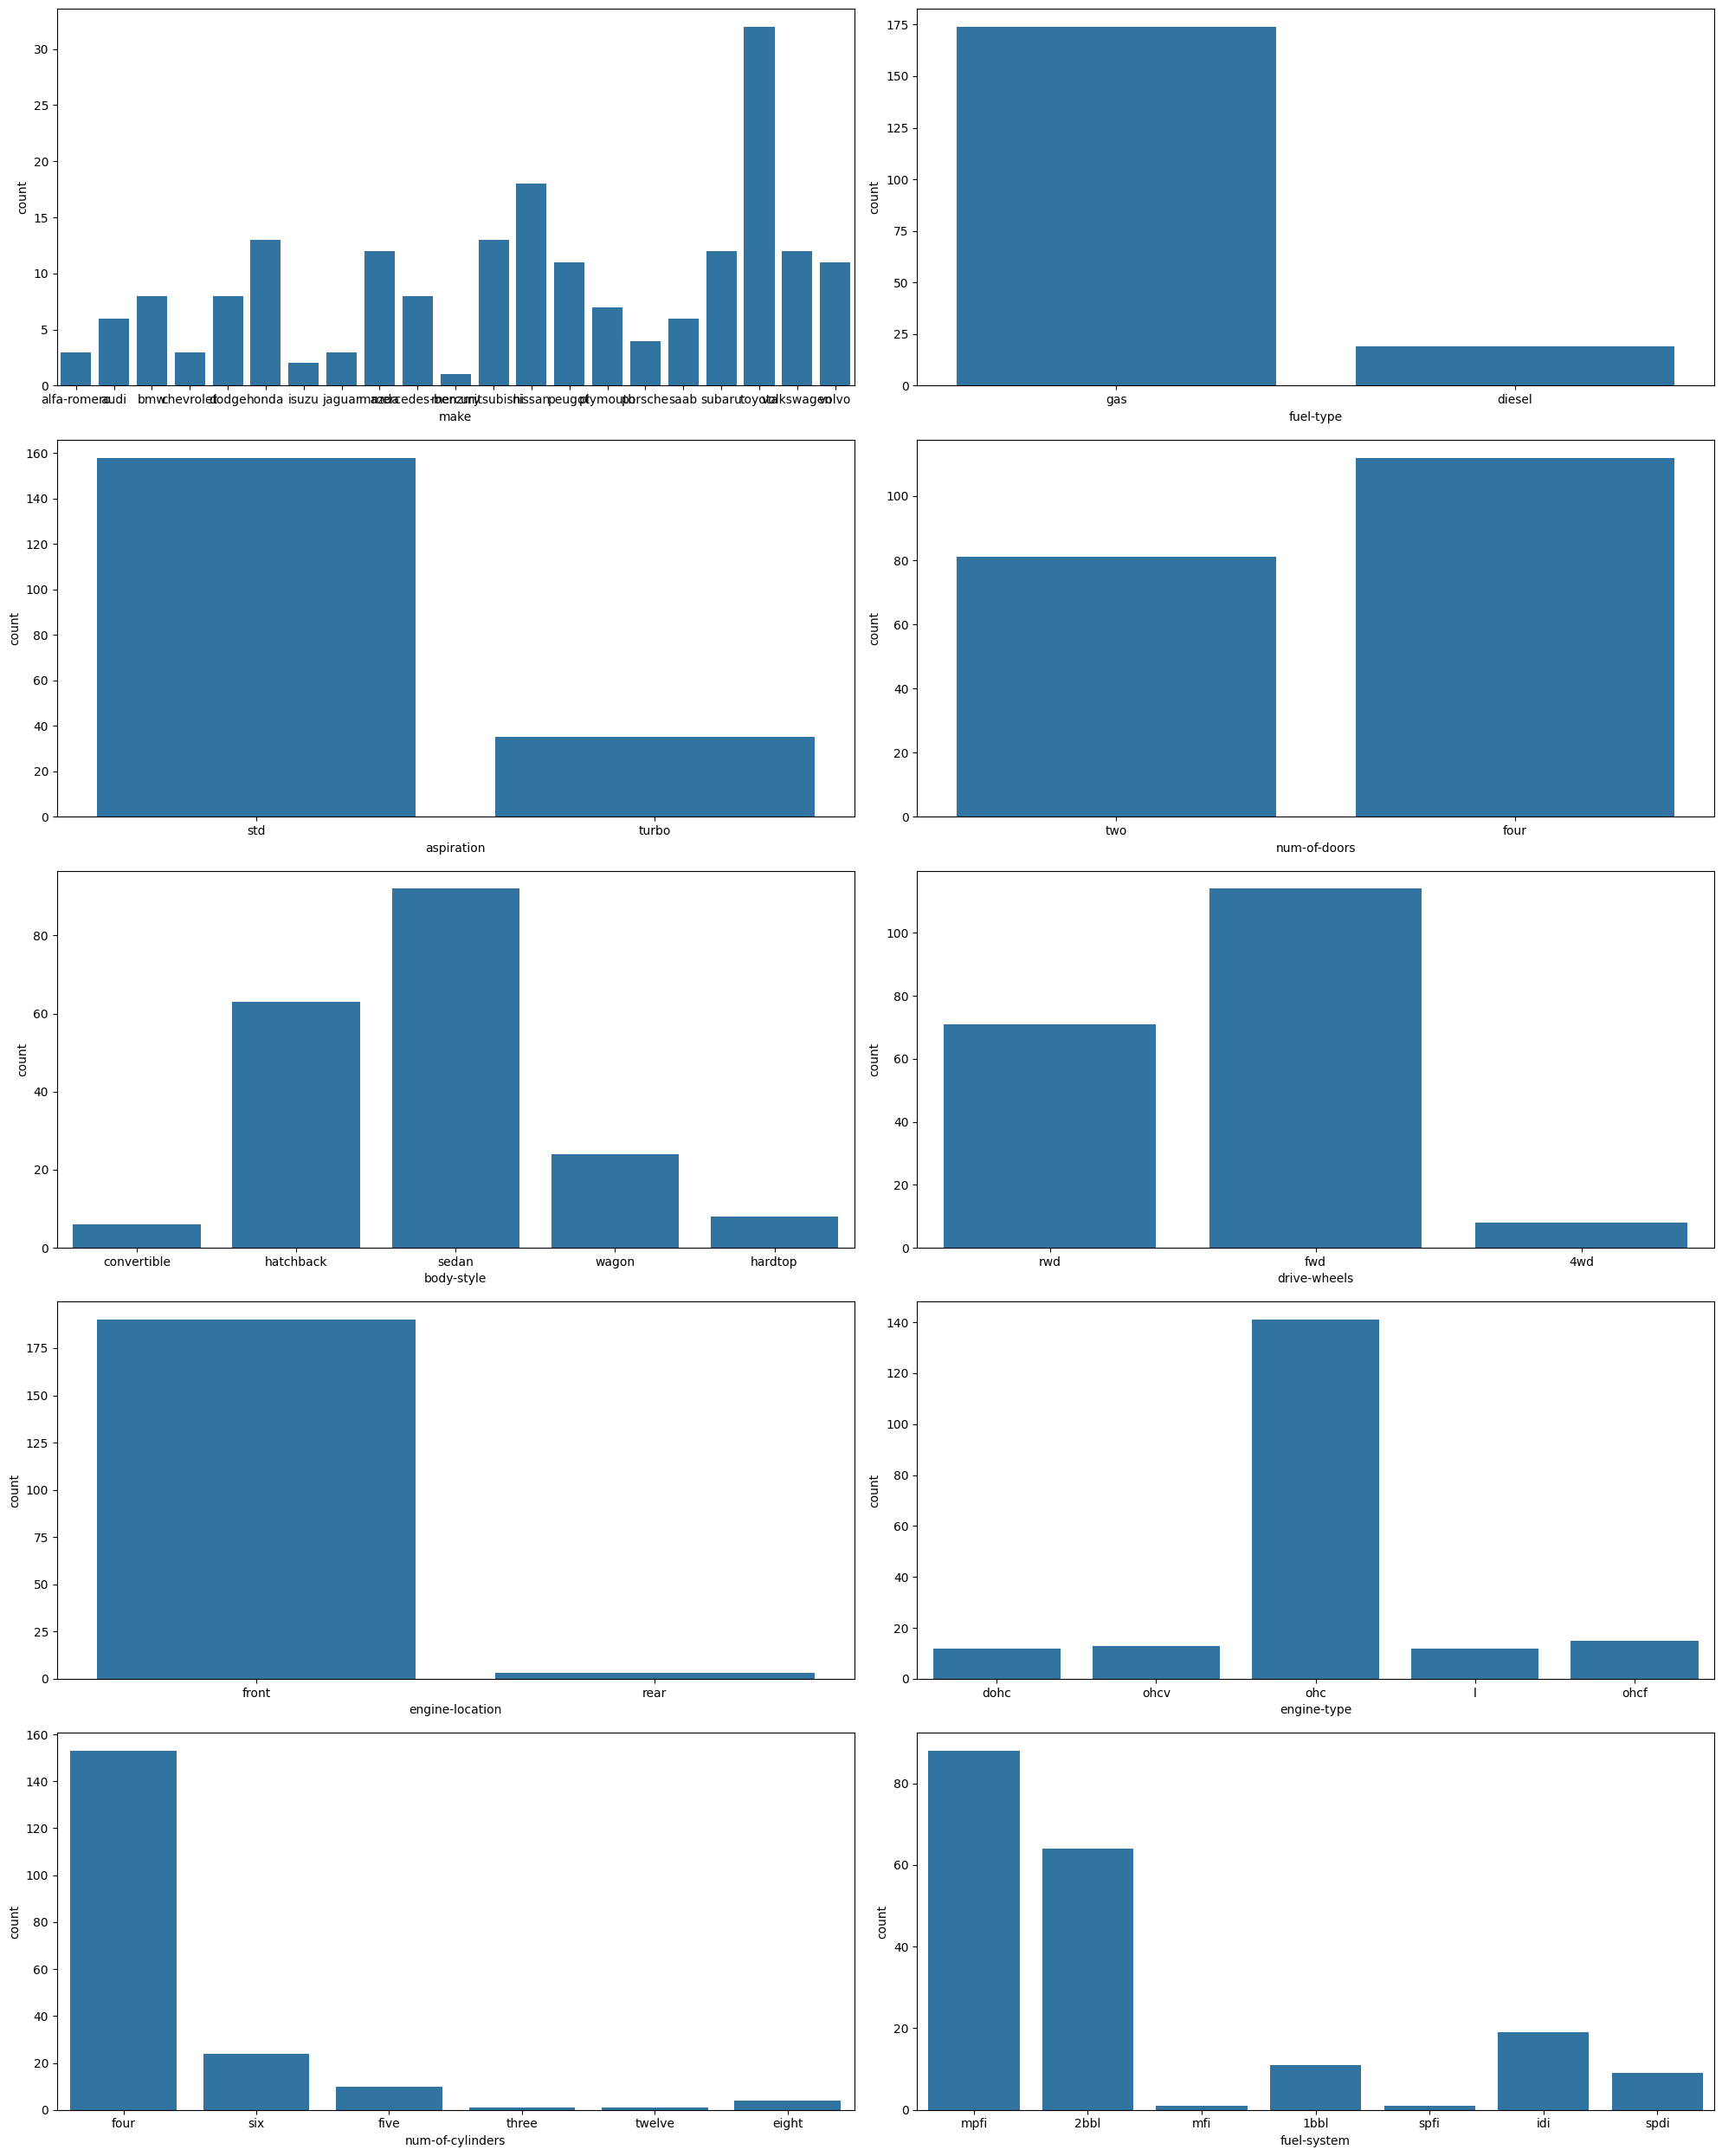

In [17]:
fig,ax=plt.subplots(5,2,figsize=(20,25))
ax=ax.flatten()
i=0
for col in cat_cols:
    sns.countplot(data=df,x=col,ax=ax[i])
    i+=1
plt.tight_layout()
plt.show()

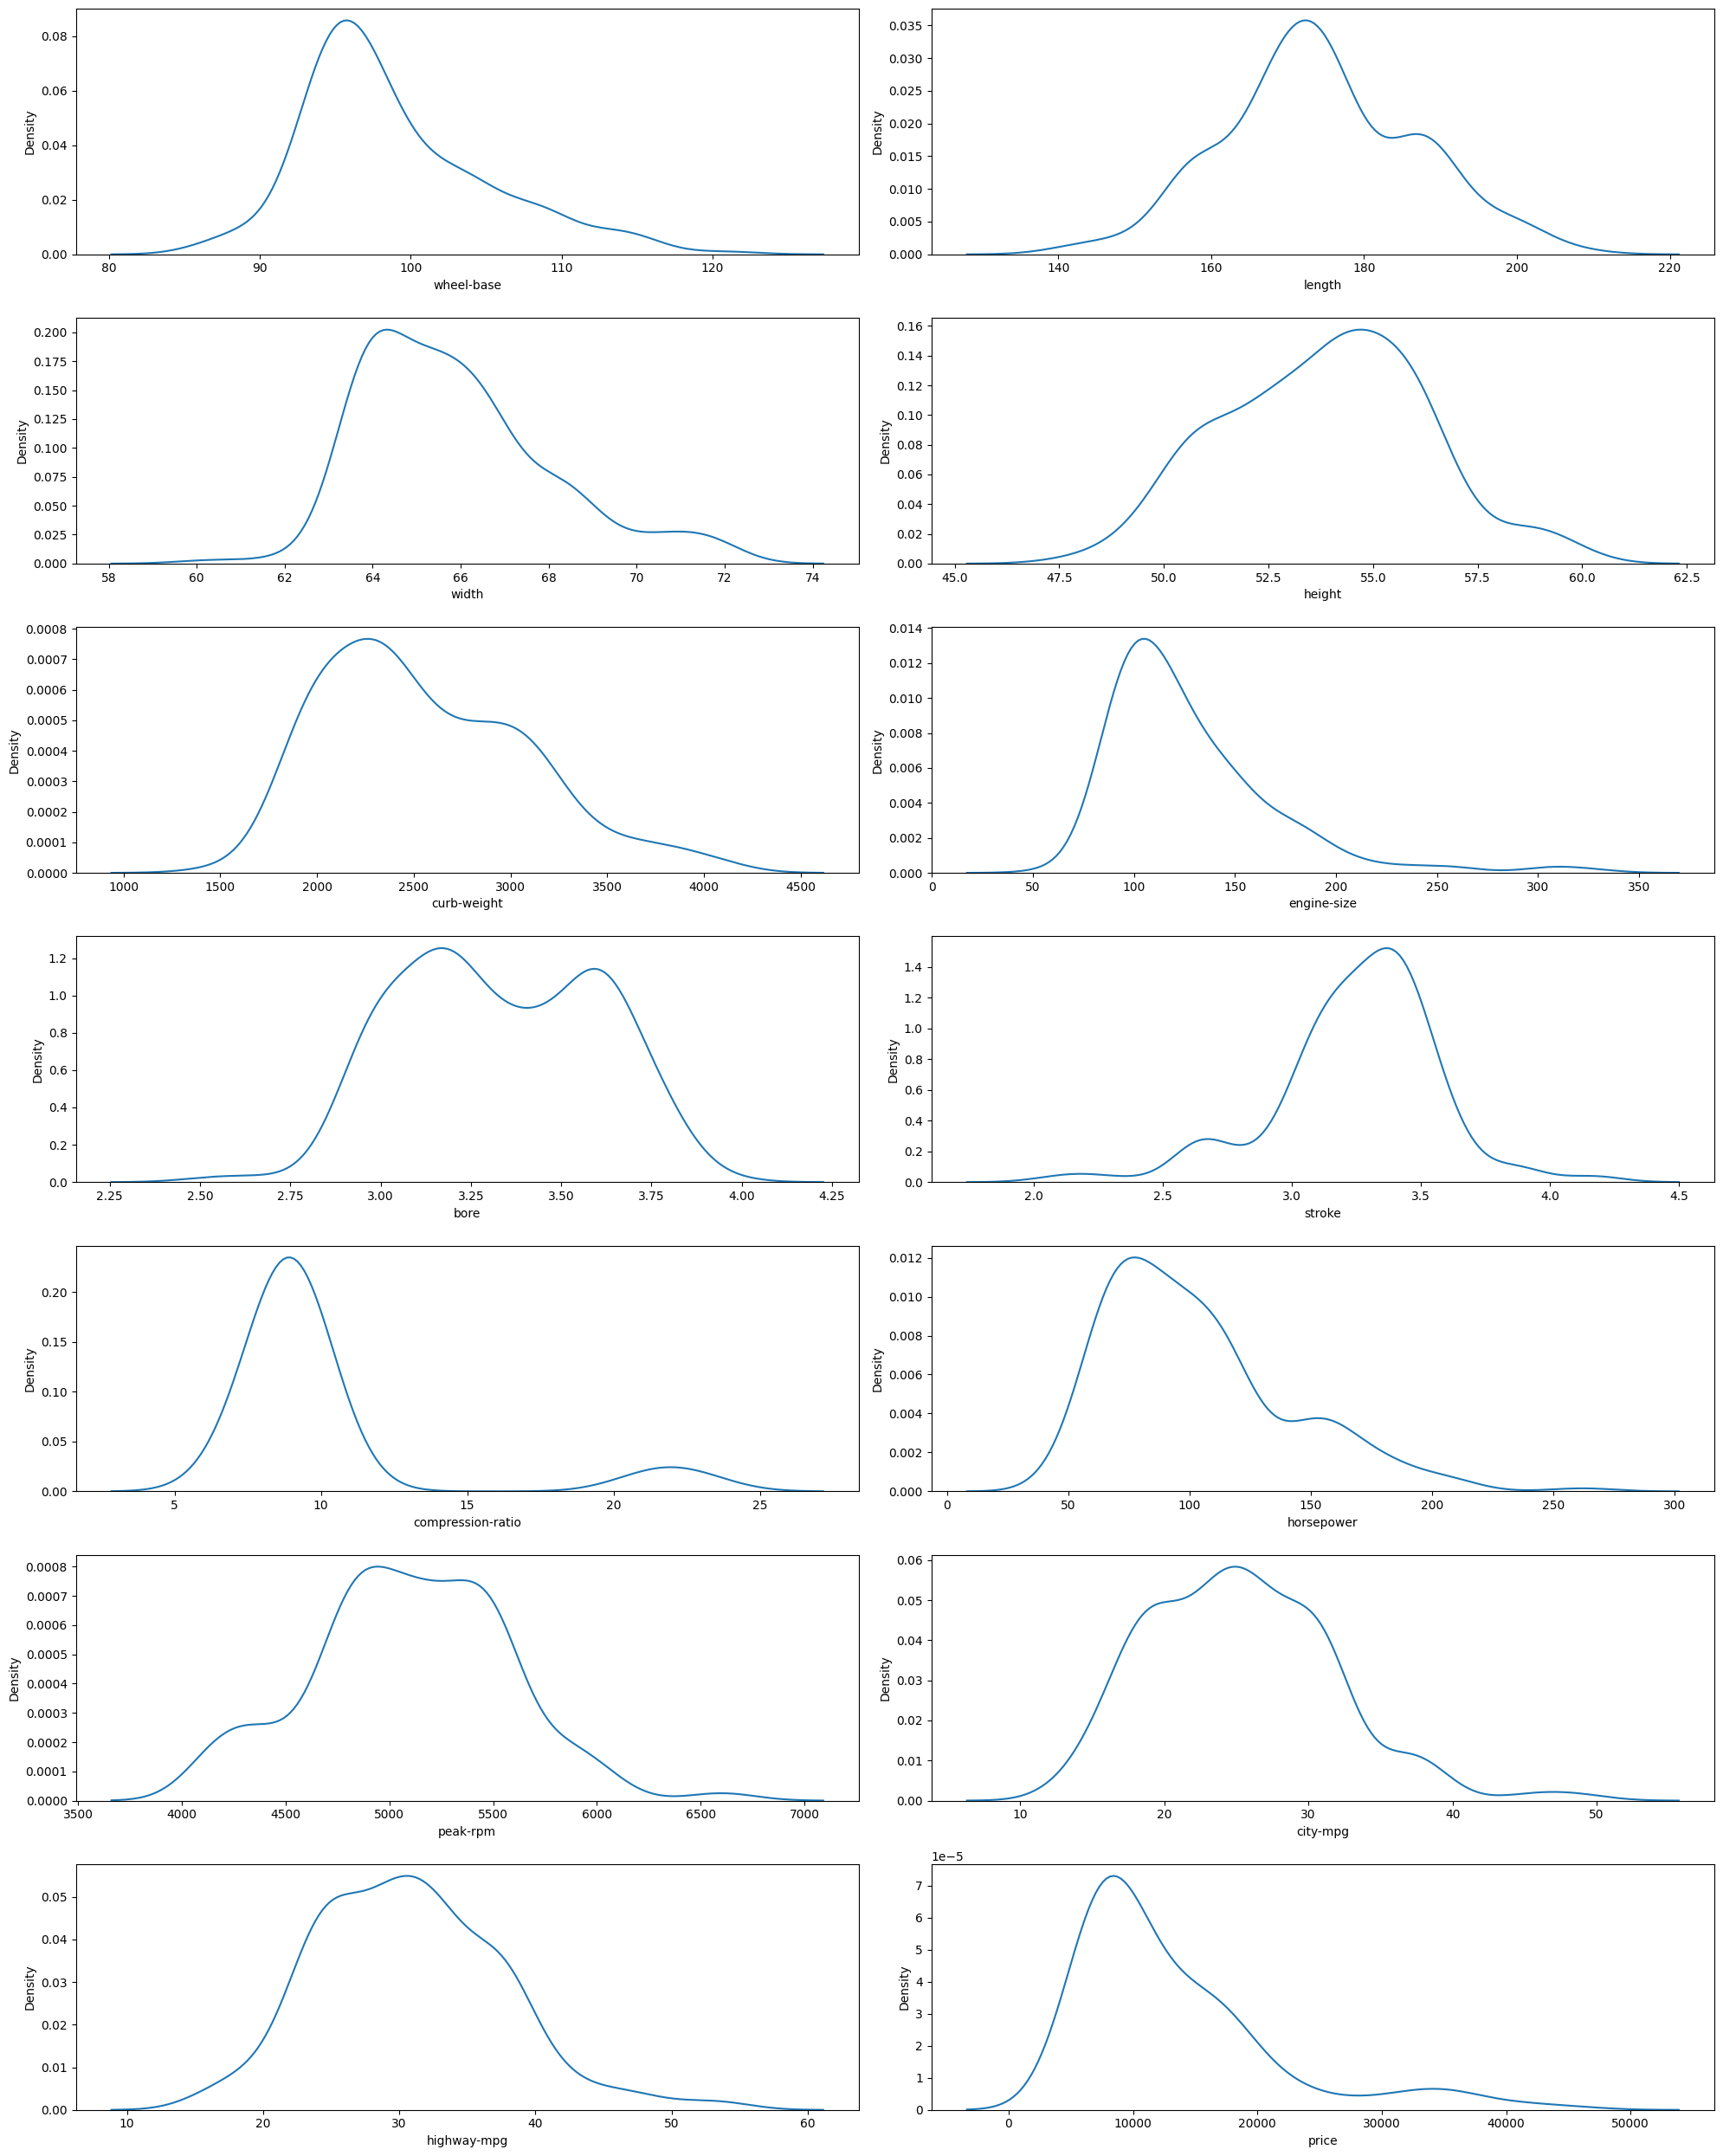

In [53]:
fig,ax=plt.subplots(7,2,figsize=(20,25))
ax=ax.flatten()
i=0
for col in not_cat_cols:
    sns.kdeplot(data=df,x=col,ax=ax[i])
    i+=1
plt.tight_layout()
plt.show()

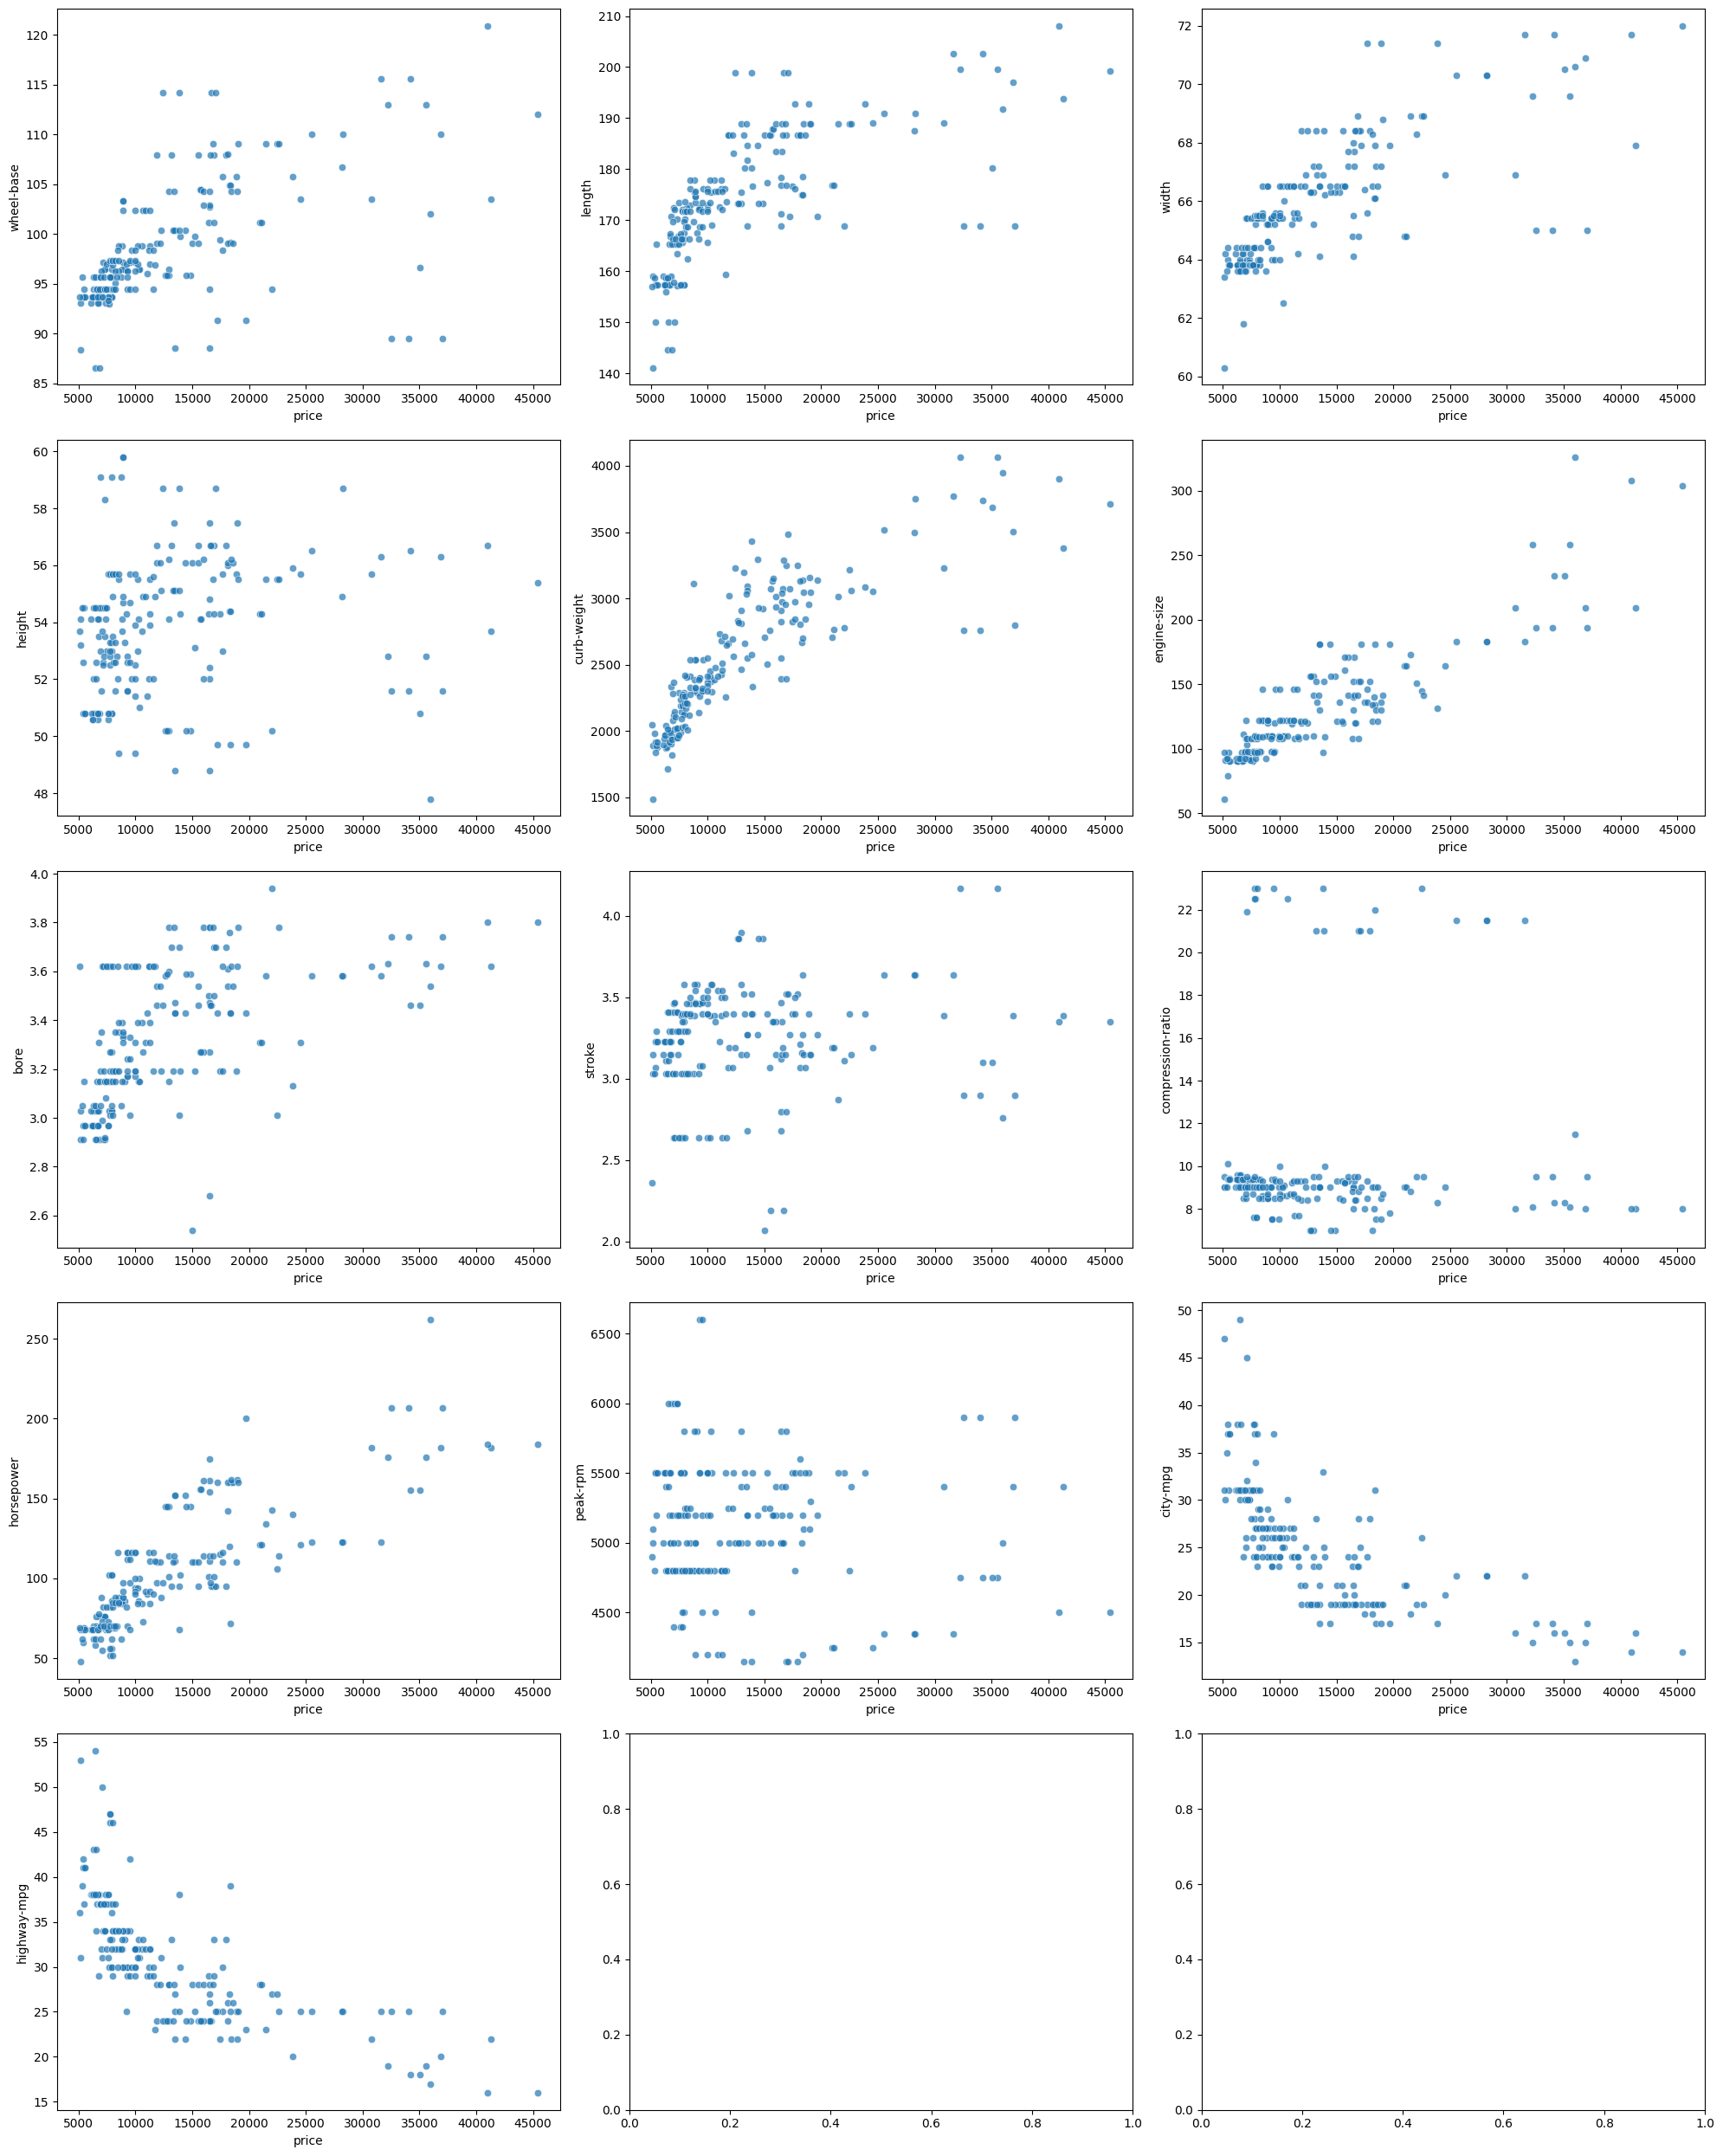

In [19]:
# numerical columns against the target variable to understand the data
fig,ax=plt.subplots(5,3,figsize=(20,25))
ax=ax.flatten()
i=0
for col in not_cat_cols:
    if col !='price':
        sns.scatterplot(data=df,x='price',y=col,ax=ax[i],alpha=0.7)
        i+=1
plt.tight_layout()
plt.show()

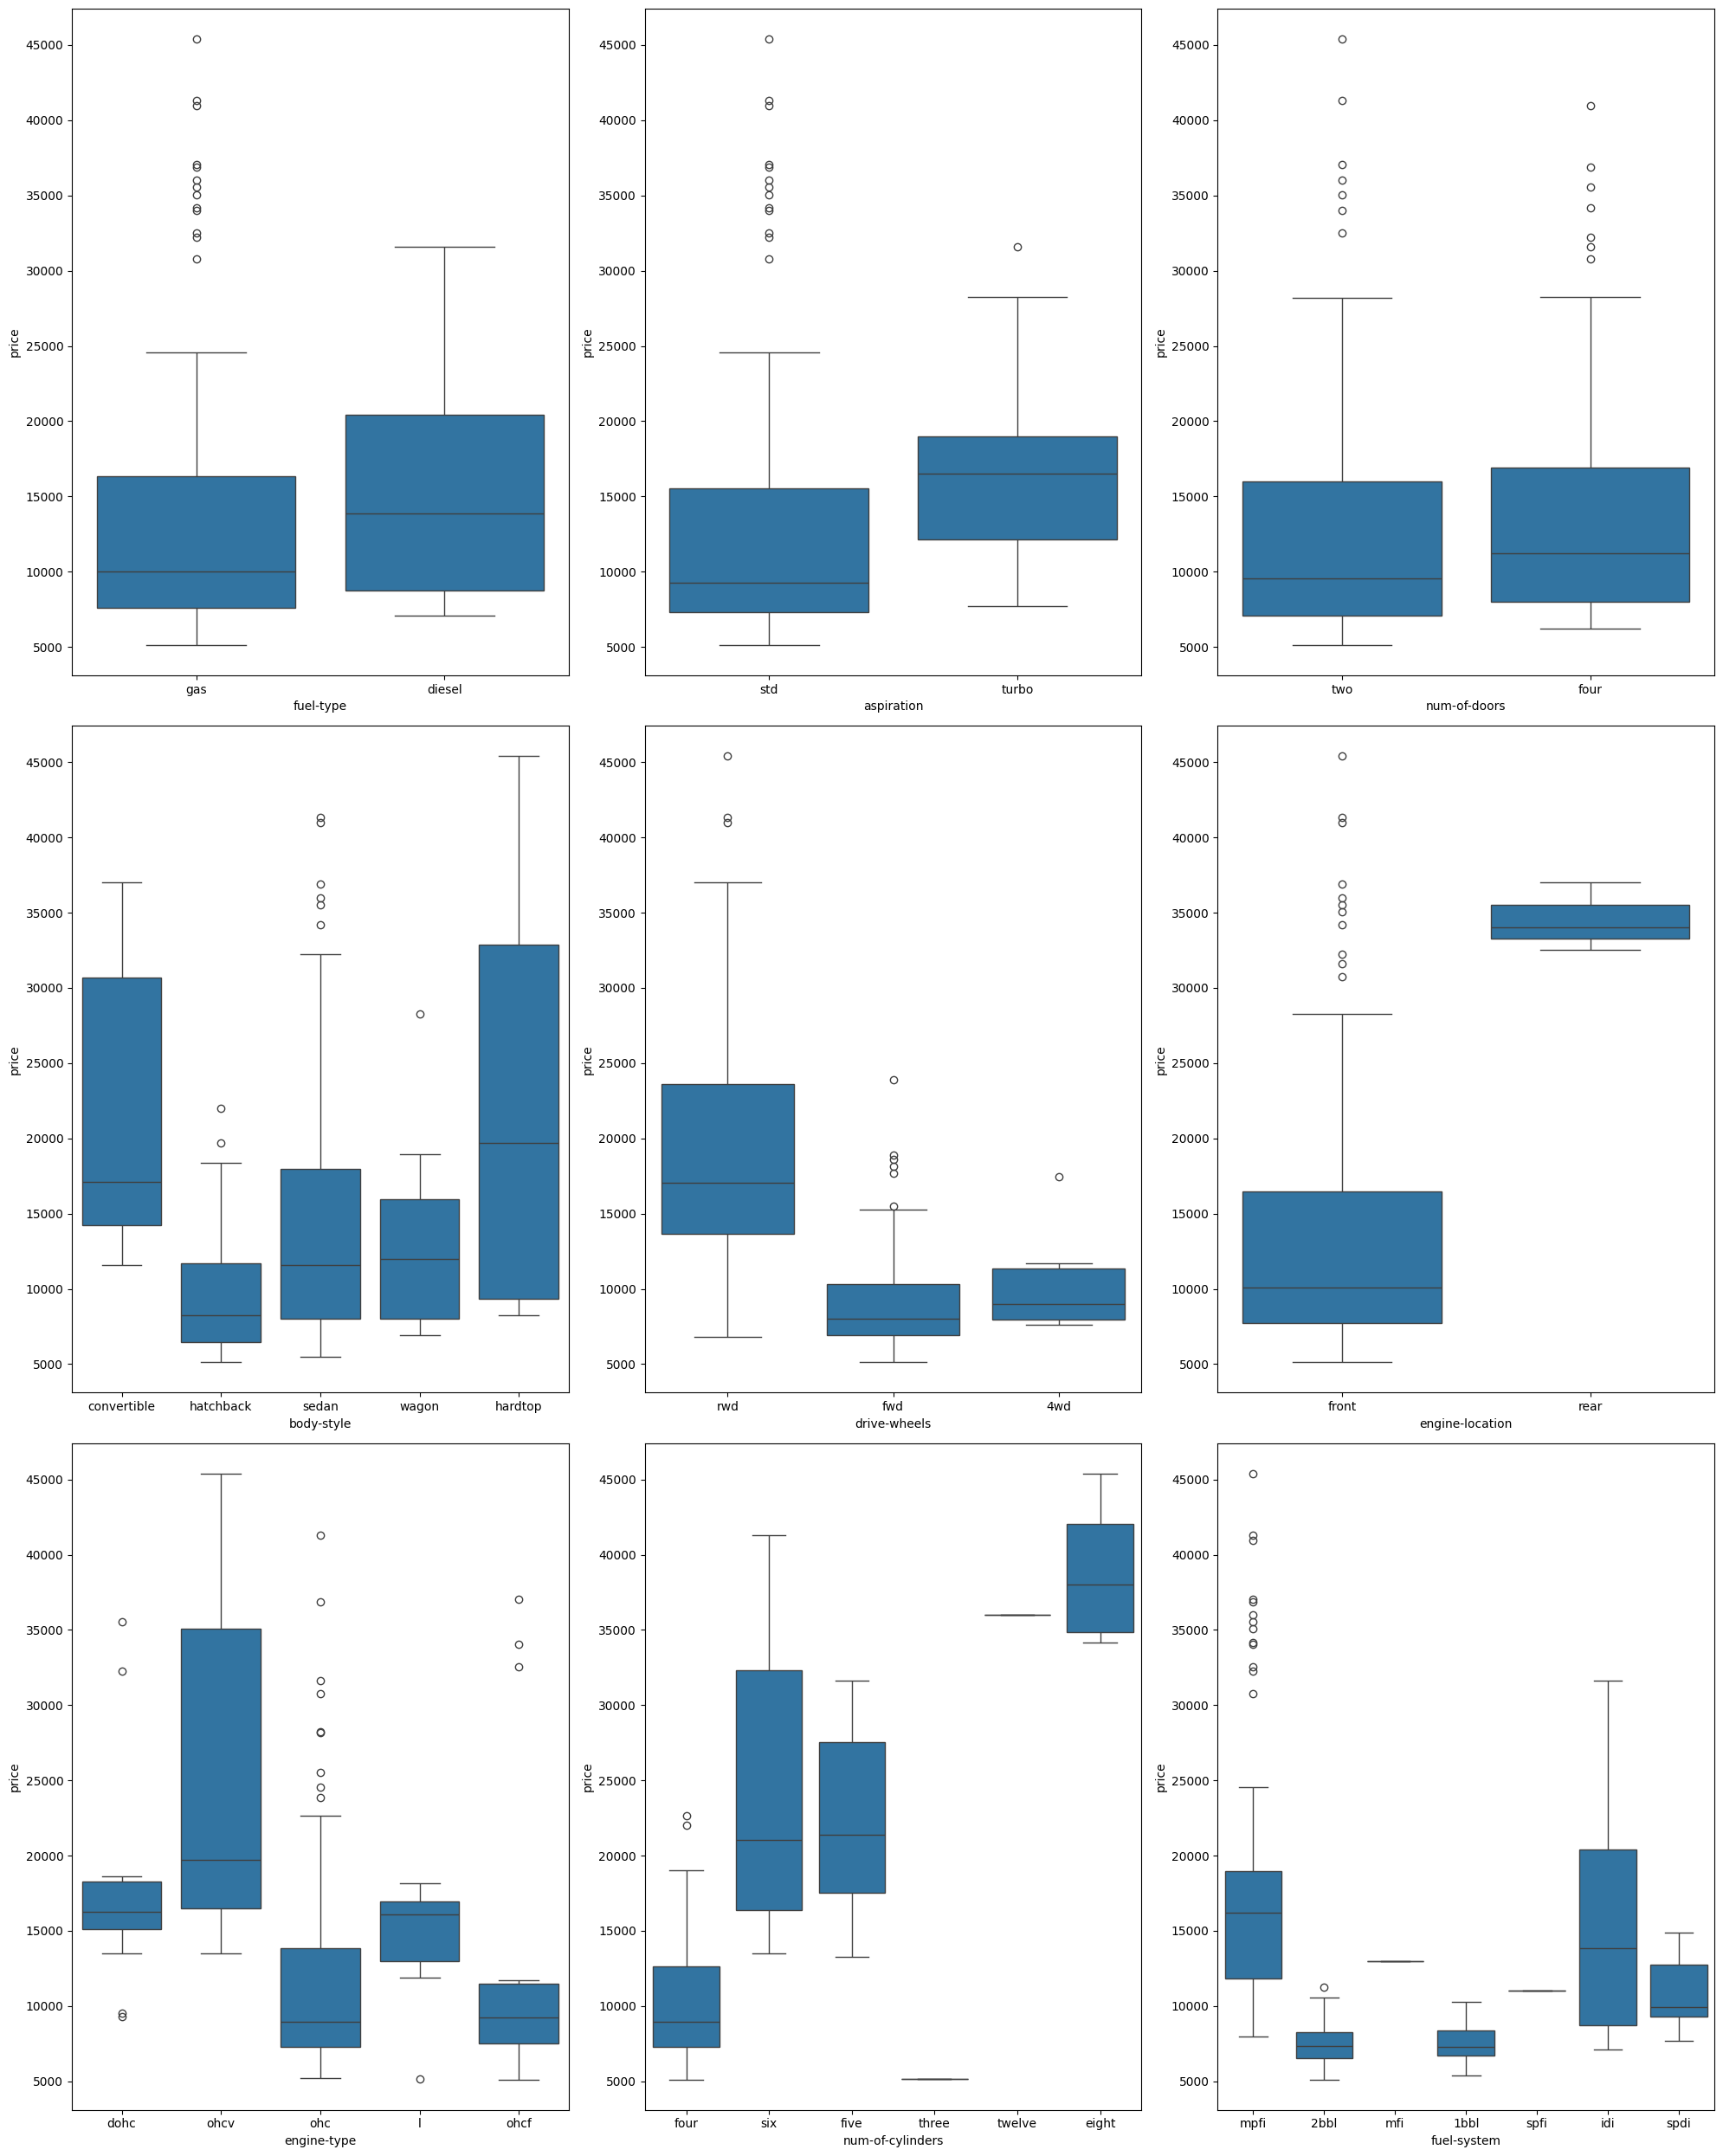

In [20]:
# cateogrical columns against the target variable to understand the data
fig,ax=plt.subplots(3,3,figsize=(20,25))
ax=ax.flatten()
i=0
for col in cat_cols:
    if col!='make': # wont be able to plot as it takes a lot of space
        sns.boxplot(data=df,y='price',x=col,ax=ax[i])
        i+=1
plt.tight_layout()
plt.show()

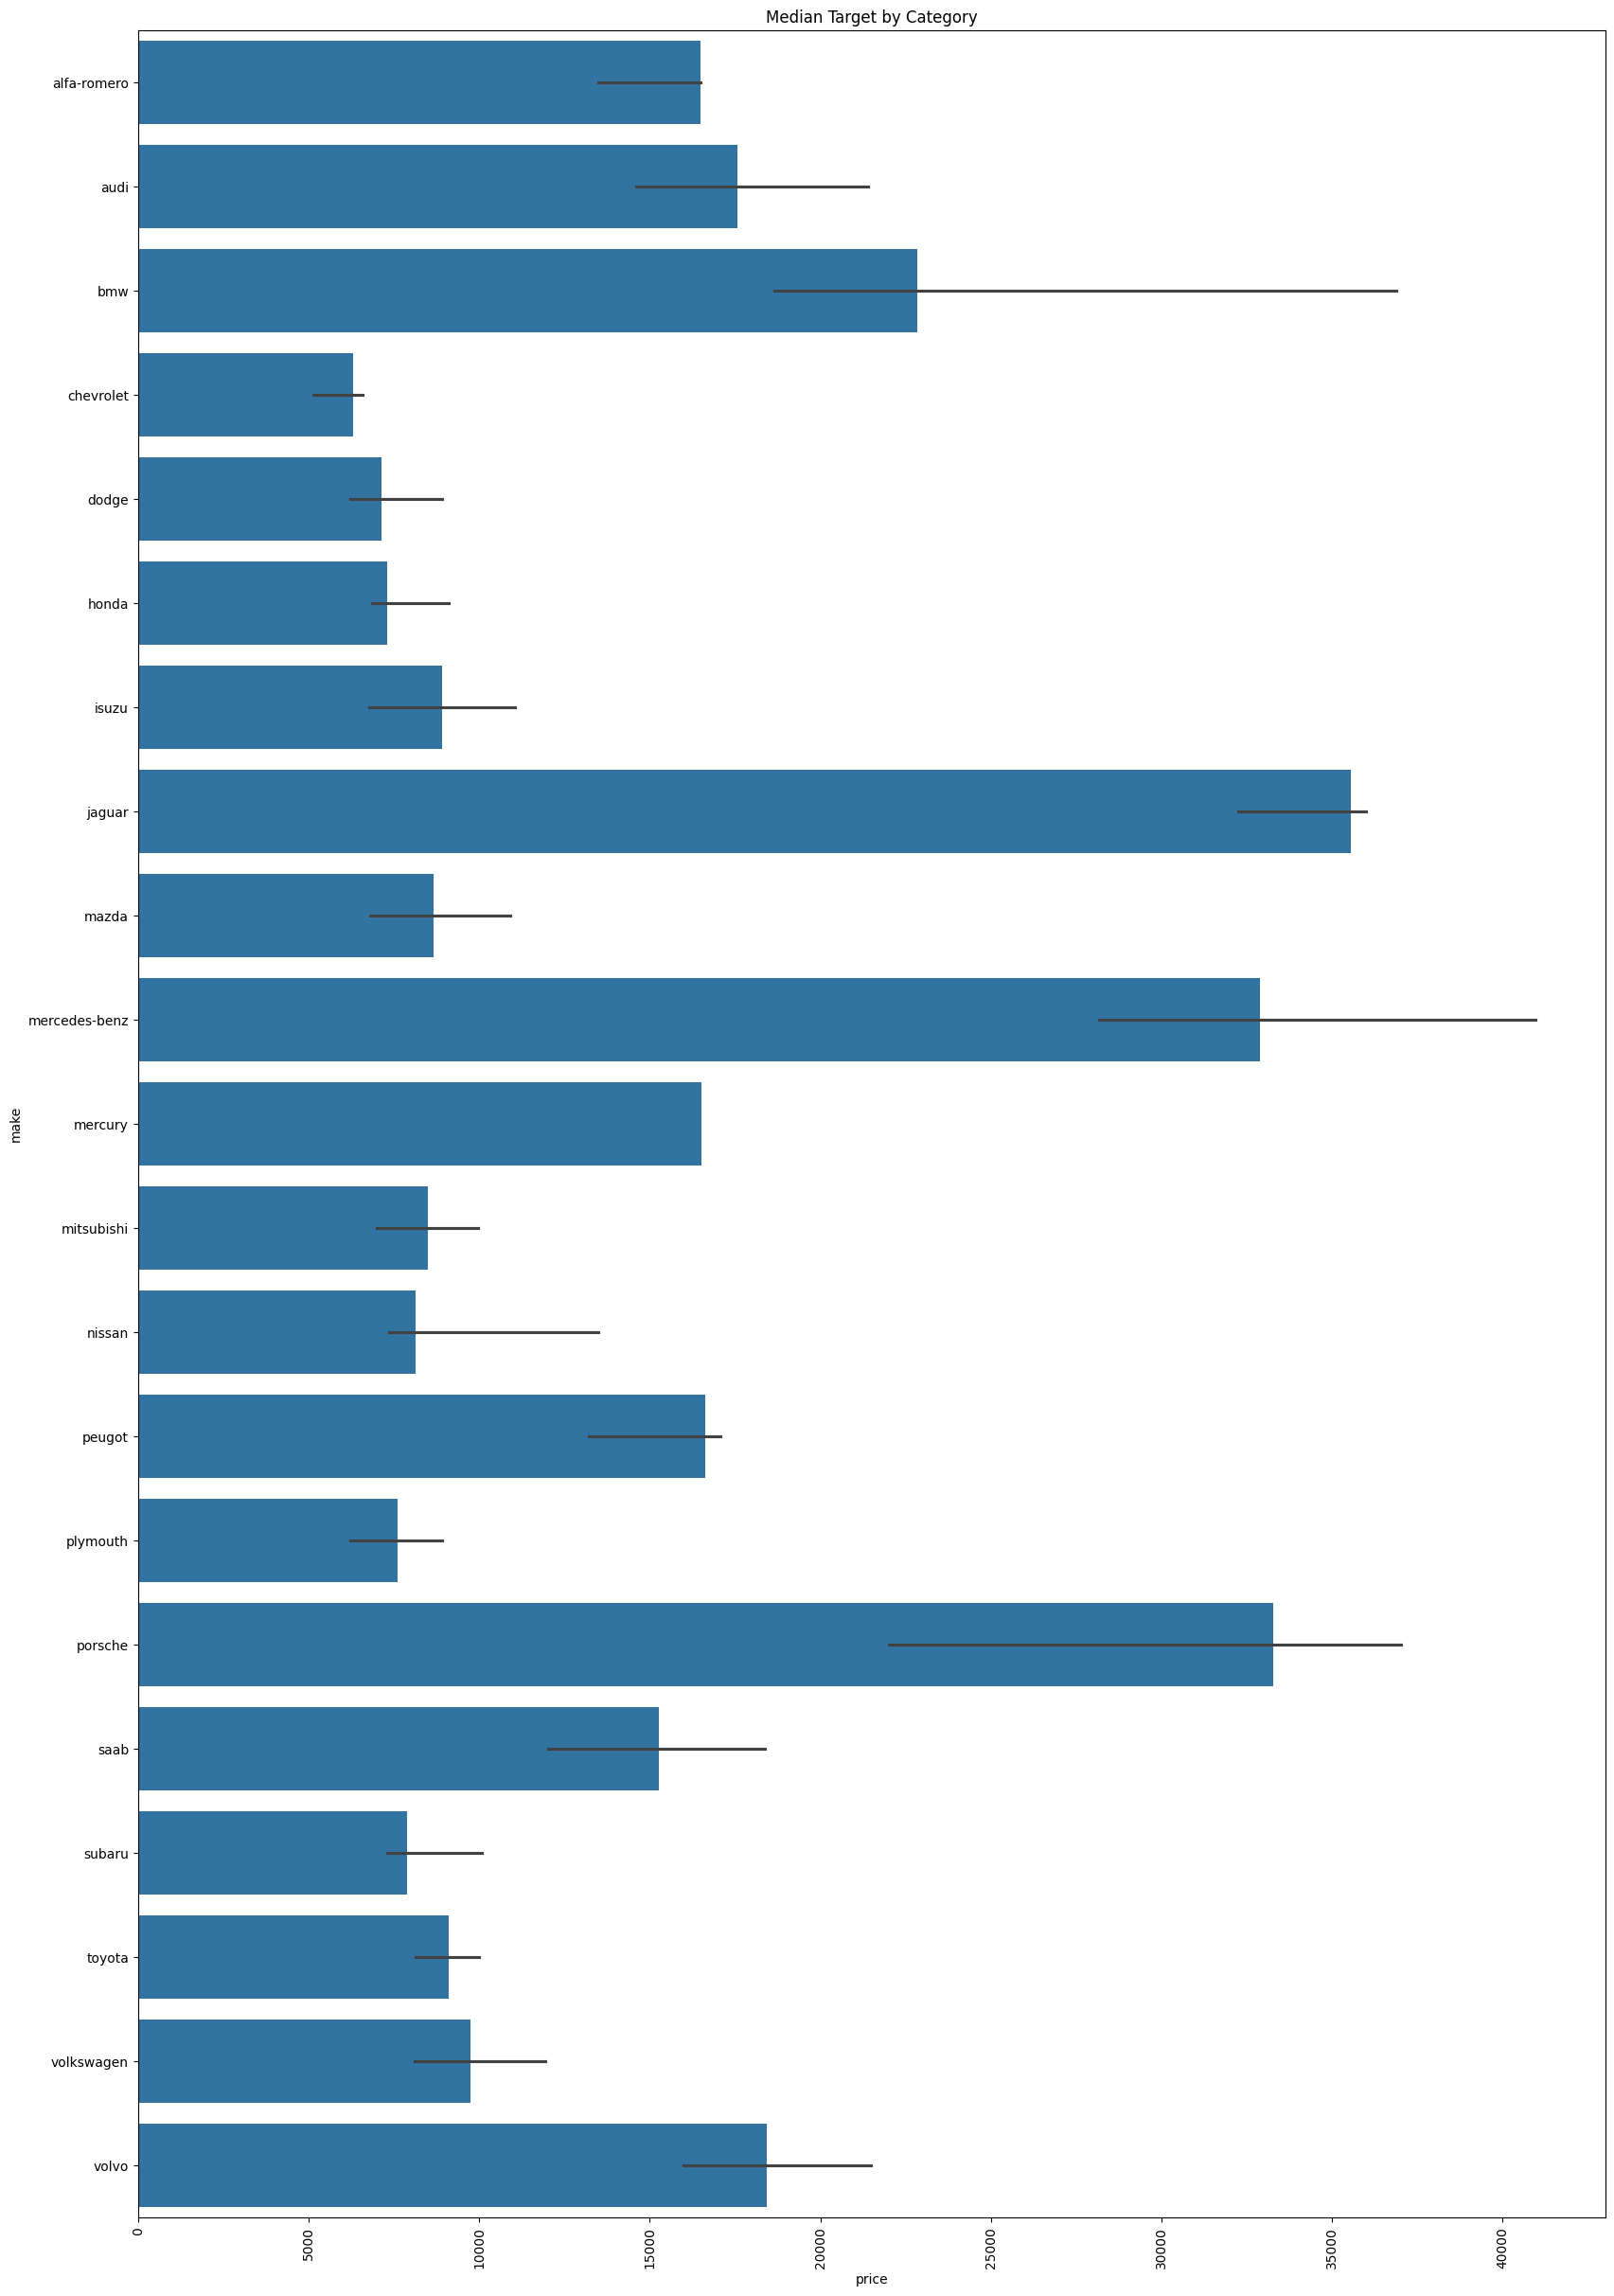

In [21]:
plt.figure(figsize=(20, 30))
sns.barplot(y='make', x='price', data=df, estimator=np.median)
plt.xticks(rotation=90)
plt.title('Median Target by Category')
plt.show()

In [ ]:
#using get_dummies:

cat_cols = df.columns[df.dtypes == 'object']
for column in cat_cols:
    new_columns = pd.get_dummies(df[column], prefix = column, dtype=float)  ### I added prefix here
#     print(new_columns)
    df = df.join(new_columns)
    
df = df.drop(columns=cat_cols) ### this one is optional, for a clean code

In [ ]:
type(cat_cols)

pandas.core.indexes.base.Index

In [ ]:
for column in cat_cols:
    print(column)

make
fuel-type
aspiration
num-of-doors
body-style
drive-wheels
engine-location
engine-type
num-of-cylinders
fuel-system


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Columns: 111 entries, wheel-base to fuel-system_spfi
dtypes: float64(111)
memory usage: 167.5 KB


In [39]:
#using LabelEncoder:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cat_cols = df.columns[df.dtypes == 'object']
for column in cat_cols:
    df[column + '_le'] = le.fit_transform(df[column])

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 35 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 193 non-null    object 
 1   fuel-type            193 non-null    object 
 2   aspiration           193 non-null    object 
 3   num-of-doors         193 non-null    object 
 4   body-style           193 non-null    object 
 5   drive-wheels         193 non-null    object 
 6   engine-location      193 non-null    object 
 7   wheel-base           193 non-null    float64
 8   length               193 non-null    float64
 9   width                193 non-null    float64
 10  height               193 non-null    float64
 11  curb-weight          193 non-null    int64  
 12  engine-type          193 non-null    object 
 13  num-of-cylinders     193 non-null    object 
 14  engine-size          193 non-null    int64  
 15  fuel-system          193 non-null    obj

In [42]:
#4:train and test:
x=df.drop(columns='price')
y=df['price']

xt,xte,yt,yte=train_test_split(x,y,random_state=20,test_size=0.2)


In [29]:
print(xt.shape,xte.shape,yt.shape,yte.shape)

(154, 23) (39, 23) (154,) (39,)


In [43]:
#5:normalize data:
# A function to normalize numerical columns

def normalize_columns(dataframe, column):
    data = dataframe[column]
    mini = min(data)
    maxi = max(data)
    
    new_data = []
    for value in data:
        new_data.append((value - mini)/(maxi - mini))
    
    dataframe[column] = new_data

for each_column in df:
    normalize_columns(df, each_column)

In [ ]:
scaler = MinMaxScaler()
df[:] = scaler.fit_transform(df)

In [36]:
#6:linear regression model training:
model = LinearRegression()
model.fit(xt, yt)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
#7:model testing:
y_pred = model.predict(xte)

In [39]:
pd.DataFrame({'Actual': yte, 'Predicted': y_pred}).head(10)	

,Actual,Predicted
28,1.187837,1.178088
161,1.197693,1.198923
59,1.229717,1.232847
13,1.226057,1.222200
51,1.197347,1.197316
132,1.198628,1.194733
180,1.210385,1.201025
127,1.190469,1.191770
104,1.215620,1.217475
126,1.180367,1.190299


In [41]:
# Model evaluation -

# checking the r2 score
print(f'R2 score = {r2_score(yte, y_pred)}')

# checking the mean squared error
print(f"Mean Squared Error = {mean_squared_error(yte, y_pred)}")

# checking the root mean squared error
print(f"The root mean squared error = {np.sqrt(mean_squared_error(yte, y_pred))}")

R2 score = 0.9369760806476571
Mean Squared Error = 1.7803341238800345e-05
The root mean squared error = 0.004219400578139073


# References:
[Kaggle_1](https://www.kaggle.com/code/pulkitmittal15/car-price-prediction-project)

[Kaggle_2](https://www.kaggle.com/code/jacopoferretti/predicting-car-prices-with-regression-pipelines)

[Kaggle_3](https://www.kaggle.com/code/anshulsingh19/car-price-prediction-multiple-linear-regression)

[Kaggle_4](https://www.kaggle.com/code/samanyuk/car-price-using-a-simple-random-forest)

[Kaggle_5](https://www.kaggle.com/code/gadigevishalsai/car-sales-price-prediction-eda-regression)

[github](https://github.com/roshancyriacmathew/Car-price-prediction-using-Linear-regression-Machine-Learning-Project)

[pandas](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)

[sklearn](https://scikit-learn.org/stable/getting_started.html)

[LabelEncoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html)

[MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html)

[get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)

[medium](https://medium.com/data-folks-indonesia/powering-up-your-pandas-part-ii-label-encoding-and-one-hot-encoding-dac0fce045da)